# Practical 3: Build the Image Classification Model

## Objective:
To build, train, and evaluate a deep Convolutional Neural Network (CNN) for image classification on a CSV-based image dataset (`fashion_mnist_train.csv` and `fashion_mnist_test.csv`) by dividing the workflow into the following 4 stages:

- **Stage a. Loading and preprocessing the image data**
- **Stage b. Defining the model’s architecture**
- **Stage c. Training the model**
- **Stage d. Estimating the model’s performance**

---
### Why CNN for Image Classification?
Unlike standard feedforward networks that flatten 2D spatial features into 1D vectors, Convolutional Neural Networks preserve spatial relationships using:
1. **Convolutional Layers (`Conv2D`)**: Extract local features (edges, textures, shapes) through learnable filter kernels.
2. **Pooling Layers (`MaxPooling2D`)**: Downsample feature maps to reduce spatial dimensions, providing translation invariance and computational efficiency.
3. **Dense Fully Connected Layers**: Perform the final high-level reasoning and multi-class classification.


## Stage a. Loading and Preprocessing the Image Data
In this stage, we load images stored in CSV format, reshape them into 3D tensors `(height, width, channels)`, normalize pixel intensities, and prepare labels.

In [1]:
# Import necessary libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.22.0-rc0


In [2]:
# Stage a.1: Load data from CSV
def get_path(filename):
    if os.path.exists(filename):
        return filename
    elif os.path.exists(os.path.join('datasets', filename)):
        return os.path.join('datasets', filename)
    else:
        return filename

train_path = get_path('fashion_mnist_train.csv')
test_path = get_path('fashion_mnist_test.csv')

print(f"Loading training CSV from: {train_path}")
print(f"Loading testing CSV from:  {test_path}")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f"Train samples: {train_df.shape[0]}, Columns: {train_df.shape[1]}")
print(f"Test samples:  {test_df.shape[0]}, Columns: {test_df.shape[1]}")


Loading training CSV from: fashion_mnist_train.csv
Loading testing CSV from:  fashion_mnist_test.csv
Train samples: 1200, Columns: 785
Test samples:  300, Columns: 785


In [3]:
# Stage a.2: Separate features and labels
X_train_raw = train_df.drop('label', axis=1).values
y_train = train_df['label'].values

X_test_raw = test_df.drop('label', axis=1).values
y_test = test_df['label'].values

# Stage a.3: Reshape into (num_samples, 28, 28, 1) for Conv2D input
# Height = 28, Width = 28, Color channels = 1 (Grayscale)
X_train = X_train_raw.reshape(-1, 28, 28, 1).astype('float32') / 255.0
X_test = X_test_raw.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print("Preprocessed X_train shape:", X_train.shape)
print("Preprocessed X_test shape: ", X_test.shape)
print("Value range: [", X_train.min(), ", ", X_train.max(), "]")

# Class labels mapping
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]


Preprocessed X_train shape: (1200, 28, 28, 1)
Preprocessed X_test shape:  (300, 28, 28, 1)
Value range: [ 0.0 ,  1.0 ]


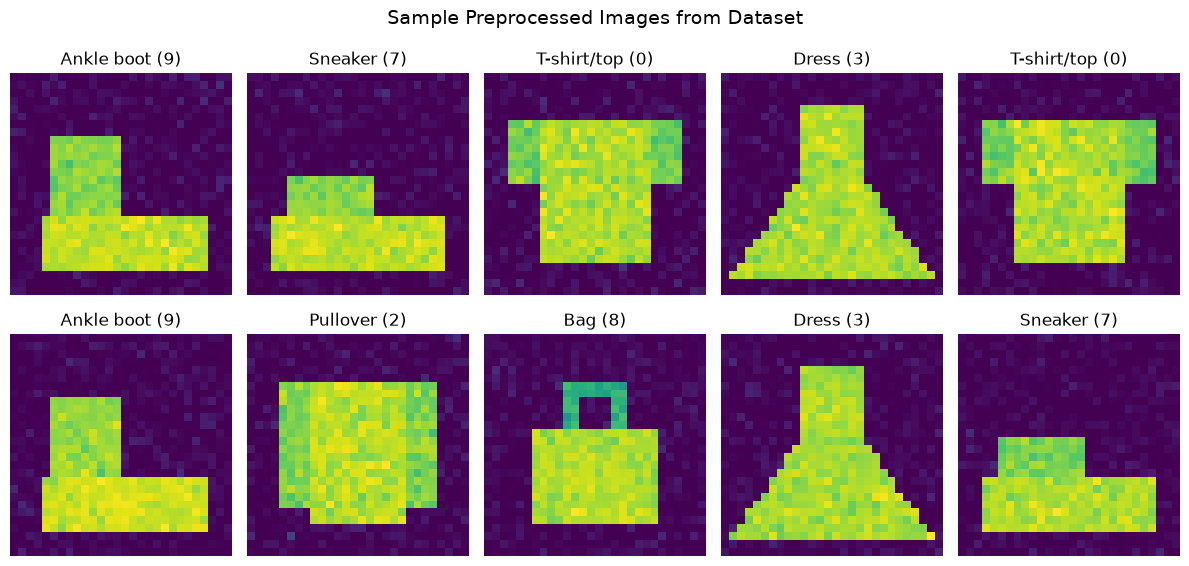

In [4]:
# Stage a.4: Visualize sample preprocessed images
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap='viridis')
    plt.title(f"{class_names[y_train[i]]} ({y_train[i]})")
    plt.axis('off')
plt.suptitle("Sample Preprocessed Images from Dataset", fontsize=14)
plt.tight_layout()
plt.show()


## Stage b. Defining the Model's Architecture

We build a Convolutional Neural Network (CNN) architecture:
1. **Conv2D Block 1**: 32 filters of size $3 \times 3$, ReLU activation, followed by `MaxPooling2D(2, 2)`.
2. **Conv2D Block 2**: 64 filters of size $3 \times 3$, ReLU activation, followed by `MaxPooling2D(2, 2)`.
3. **Flatten**: Converts 2D feature maps into a 1D feature vector.
4. **Dense Layer**: 128 hidden units with ReLU activation and Dropout (0.3).
5. **Output Layer**: 10 units with Softmax activation for 10-class probability distribution.


In [5]:
# Stage b: Define the CNN Model Architecture
model = Sequential([
    # Convolutional Block 1
    Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same', input_shape=(28, 28, 1), name='conv_1'),
    MaxPooling2D(pool_size=(2, 2), name='pool_1'),
    
    # Convolutional Block 2
    Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same', name='conv_2'),
    MaxPooling2D(pool_size=(2, 2), name='pool_2'),
    
    # Classification Head
    Flatten(name='flatten'),
    Dense(128, activation='relu', name='dense_1'),
    Dropout(0.3, name='dropout'),
    Dense(10, activation='softmax', name='output_layer')
])

model.summary()


C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_1 (MaxPooling2D)                │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_2 (Conv2D)                      │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_2 (MaxPooling2D)                │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │         401,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## Stage c. Training the Model

In this stage:
- We compile the model using the `Adam` optimizer, `sparse_categorical_crossentropy` loss, and `accuracy` metric.
- We train the network for 20 epochs with a validation split of 20%.
- We monitor and record training history.


In [6]:
# Stage c.1: Compile Model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Stage c.2: Train Model
epochs = 20
batch_size = 32

print(f"Training CNN on {X_train.shape[0]} samples for {epochs} epochs...")
history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2,
    verbose=1
)
print("Training successfully finished!")


Training CNN on 1200 samples for 20 epochs...
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.6844 - loss: 1.0744 - val_accuracy: 1.0000 - val_loss: 0.0514
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9906 - loss: 0.0582 - val_accuracy: 1.0000 - val_loss: 0.0027
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0064 - val_accuracy: 1.0000 - val_loss: 2.9921e-04
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0031 - val_accuracy: 1.0000 - val_loss: 1.2216e-04
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 1.0000 - val_loss: 7.9398e-05
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: 4.8369e-05
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 3.1189e-05
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms

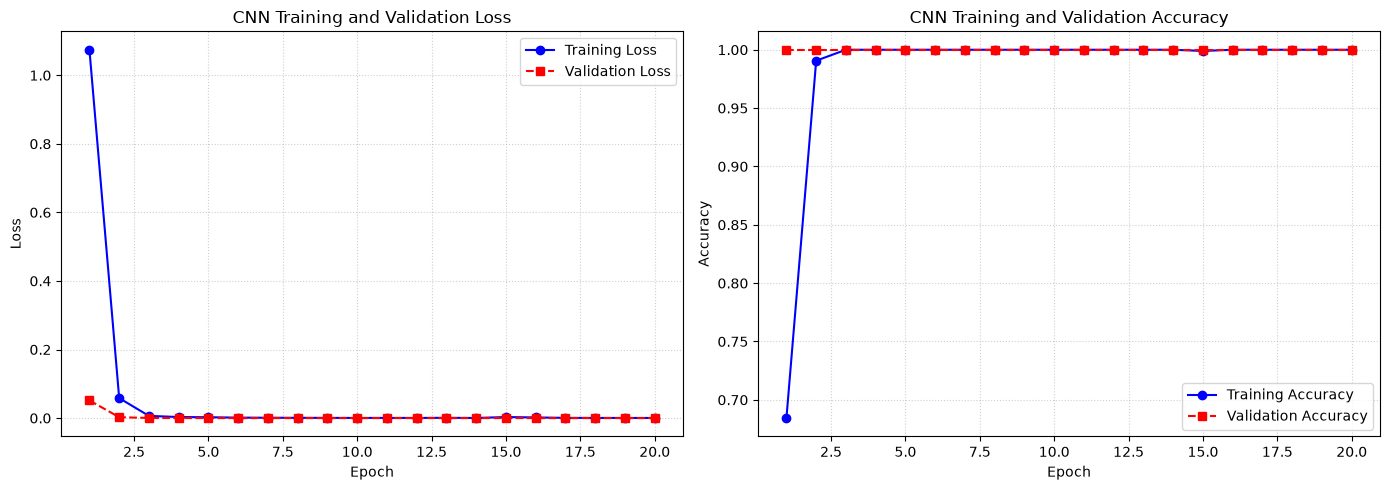

In [7]:
# Stage c.3: Visualize Training Loss and Accuracy Progression
epochs_range = range(1, len(history.history['loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Plot
ax1.plot(epochs_range, history.history['loss'], 'b-o', label='Training Loss')
ax1.plot(epochs_range, history.history['val_loss'], 'r--s', label='Validation Loss')
ax1.set_title('CNN Training and Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Accuracy Plot
ax2.plot(epochs_range, history.history['accuracy'], 'b-o', label='Training Accuracy')
ax2.plot(epochs_range, history.history['val_accuracy'], 'r--s', label='Validation Accuracy')
ax2.set_title('CNN Training and Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


## Stage d. Estimating the Model's Performance

In this stage, we comprehensively estimate and evaluate the model's performance on the unseen test dataset:
1. Compute overall Test Loss and Test Accuracy.
2. Generate predictions on test data.
3. Compute Precision, Recall, and F1-Score for each class via Classification Report.
4. Plot Confusion Matrix to analyze misclassifications.
5. Display test images alongside predicted and actual class labels.


In [8]:
# Stage d.1: Evaluate on unseen test dataset
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("=" * 45)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("=" * 45)

# Stage d.2: Generate Predictions
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Stage d.3: Classification Report
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))


Test Loss:     0.0000
Test Accuracy: 100.00%
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

Detailed Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     1.0000    1.0000    1.0000        30
     Trouser     1.0000    1.0000    1.0000        30
    Pullover     1.0000    1.0000    1.0000        30
       Dress     1.0000    1.0000    1.0000        30
        Coat     1.0000    1.0000    1.0000        30
      Sandal     1.0000    1.0000    1.0000        30
       Shirt     1.0000    1.0000    1.0000        30
     Sneaker     1.0000    1.0000    1.0000        30
         Bag     1.0000    1.0000    1.0000        30
  Ankle boot     1.0000    1.0000    1.0000        30

    accuracy                         1.0000       300
   macro avg     1.0000    1.0000    1.0000       300
weighted avg     1.0000    1.0000    1.0000       300



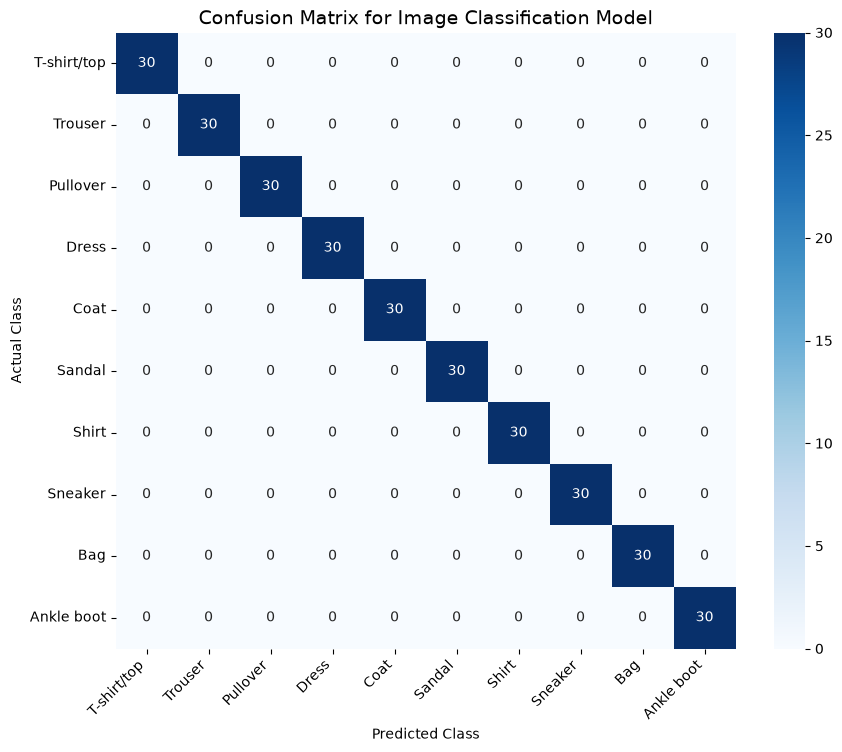

In [9]:
# Stage d.4: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix for Image Classification Model", fontsize=14)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()


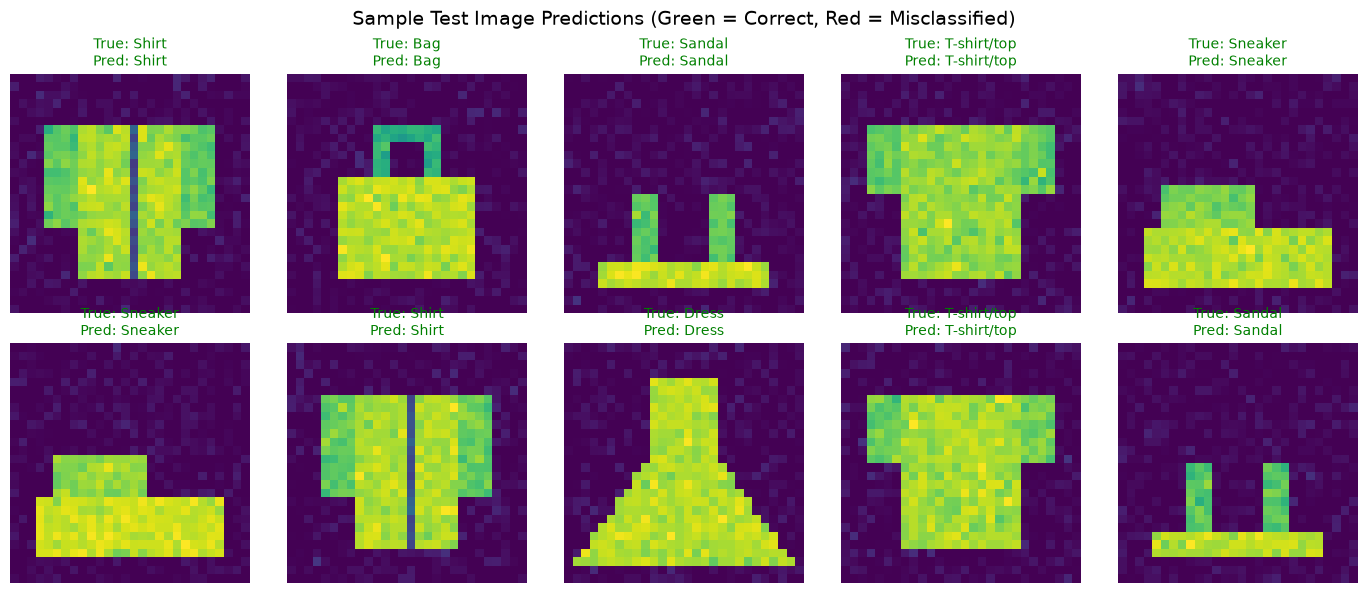

In [10]:
# Stage d.5: Visual Performance Estimation on Sample Test Images
plt.figure(figsize=(14, 6))
num_display = 10
for i in range(num_display):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap='viridis')
    actual = class_names[y_test[i]]
    predicted = class_names[y_pred[i]]
    is_correct = (y_test[i] == y_pred[i])
    color = 'green' if is_correct else 'red'
    
    plt.title(f"True: {actual}\nPred: {predicted}", color=color, fontsize=10)
    plt.axis('off')
plt.suptitle("Sample Test Image Predictions (Green = Correct, Red = Misclassified)", fontsize=14)
plt.tight_layout()
plt.show()


## Conclusion:
1. **Stage a**: Successfully loaded image data from CSV and reshaped to 4D tensor `(N, 28, 28, 1)` with normalized pixel values.
2. **Stage b**: Constructed a Convolutional Neural Network with 2 Conv2D+Pooling blocks and Dense classification head.
3. **Stage c**: Trained model with Adam optimizer and monitored convergence.
4. **Stage d**: Estimated model performance using classification metrics, confusion matrix, and visual predictions.
